# Proyecto Final - Corte 3: Control y Trazabilidad de Inventarios con RFID
* **Empresa:** LogiNeiva S.A.S. (Ficticia)
* **Estudiante:** Julián Andrés Cabrera Murcia , Jhan Michael Bermeo Trujillo, Nicol Alexandra Vargas
* **Asignatura:** Electiva VI - Ciencia de Datos

## Pregunta de Investigación (Concreta y Medible)
> *¿Qué categorías y zonas de la bodega concentran las diferencias entre la ubicación registrada en el sistema y la ubicación detectada por tecnología RFID durante el periodo comprendido entre enero y diciembre de 2026?*

## Grano de la Tabla Principal
Cada fila de la tabla principal de lecturas y movimientos representa **un evento único de escaneo o transacción de un activo RFID** (identificado por su código EPC único), registrado con su marca temporal, potencia de señal, estado físico y ubicación física dentro de la tienda o bodega de LogiNeiva S.A.S.

1. Introducción


La gestión eficiente de inventarios representa un factor fundamental para el desempeño estratégico y operativo de las organizaciones modernas, especialmente en aquellas empresas dedicadas a la comercialización y distribución que manejan grandes volúmenes de mercancías y requieren información veraz, oportuna y actualizada para la toma de decisiones gerenciales. En este contexto, la implementación de tecnologías de identificación automática y captura de datos, tales como la radiofrecuencia (**RFID - Radio Frequency Identification**), constituye un avance crucial frente a los métodos tradicionales de control manual o códigos de barras. La tecnología RFID permite mejorar de forma sustancial el seguimiento, la localización y la trazabilidad de los artículos almacenados, proporcionando visibilidad en tiempo real sobre su estado y ubicación exacta dentro de la cadena de suministro y la infraestructura logística.

En el presente proyecto se analiza y modela una propuesta integral de implementación de tecnología RFID orientada al control y trazabilidad de inventarios en la empresa ficticia **LogiNeiva S.A.S.** Para dar solución a los retos logísticos planteados, se emplea una metodología estructurada de ciencia de datos que abarca desde la simulación de un horizonte temporal robusto de **12 meses (correspondiente al ciclo anual 2026)** hasta el almacenamiento relacional. Con el fin de garantizar la **reproducibilidad técnica y metodológica** de la investigación —evitando variaciones estocásticas indeseadas en las ejecuciones posteriores—, todo el proceso de generación de datos está anclado a una **semilla institucional fija (`seed(2026)`)** en Python y NumPy.

Asimismo, dado que los entornos operacionales reales suelen presentar imperfecciones en la captura de eventos, el conjunto de datos inicial fue sometido a una auditoría estricta de calidad, documentada formalmente mediante una **bitácora de limpieza (Antes, Después y Motivo)** que detalla la eliminación de duplicados, la depuración de identificadores anómalos y la imputación estadística de valores faltantes. Finalmente, toda la información depurada y estructurada es albergada en un motor de base de datos relacional **SQLite**, facilitando la ejecución de consultas SQL avanzadas —que integran cruces lógicos (`JOIN`) y filtros temporales mediante Expresiones de Tablas Comunes (`CTEs`)— y permitiendo el cálculo de indicadores clave de desempeño (KPI) orientados a evaluar la precisión de ubicación y optimizar la toma de decisiones logísticas en LogiNeiva S.A.S.dores y recomendaciones orientadas a mejorar el desempeño logístico mediante la tecnología RFID

2. Descripción de los datos

Para dar cumplimiento a los objetivos analíticos y operativos del proyecto, se diseñó e implementó una arquitectura de datos sintética pero altamente realista, modelada sobre las dinámicas logísticas de la empresa ficticia LogiNeiva S.A.S., organización especializada en la gestión, almacenamiento y distribución de productos de consumo masivo en la región.

Con el fin de capturar la estacionalidad operativa y el comportamiento del inventario a lo largo de un ciclo anual completo, el conjunto de datos abarca un horizonte temporal de 12 meses (desde el 1 de enero hasta el 31 de diciembre de 2026). Para garantizar la reproducibilidad técnica y evitar variaciones indeseadas en los resultados ante ejecuciones múltiples del cuaderno, todo el proceso de generación aleatoria se encuentra anclado a una semilla institucional fija (seed(2026) en Python y NumPy), asegurando que las métricas, gráficos y consultas SQL mantengan una consistencia absoluta.

3. Importaciones, Semilla y Generación de Datos

Este paso inicial se implementó para establecer la base técnica y reproducible del proyecto de LogiNeiva S.A.S., integrando librerías clave de análisis y fijando una semilla institucional (seed(2026)) que garantiza que los datos sintéticos de los 12 meses y más de 1,000 registros generados sean exactamente idénticos cada vez que el cuaderno sea ejecutado. De esta manera, cumplimos con las exigencias metodológicas y de estacionalidad requeridas por el docente, evitando variaciones estocásticas indeseadas en los resultados, gráficos y consultas posteriores.

In [313]:
import os
import random
import numpy as np
import pandas as pd

# ==========================================
# 1. FIJAR SEMILLA INSTITUCIONAL (REQUISITO CLAVE)
# ==========================================
random.seed(2026)
np.random.seed(2026)

num_registros = 1200  # Más de 1,000 filas exigidas por la rúbrica

# Catálogos base de LogiNeiva S.A.S.
epc_codes = [f"303405789012345{i:04d}" for i in range(1, 250)]
categorias = ["Bebidas", "Tecnologia", "Textil", "Hogar", "Herramientas"]
fechas_base = pd.date_range(start="2026-01-01", end="2026-12-31", freq="D") # 12 meses completos
zonas = ["TIENDA - ESTANTE A", "TIENDA - ESTANTE B", "BODEGA - SECCION 1", "BODEGA - SECCION 2", "EXHIBIDOR PRINCIPAL"]
estados_tag = ["Activa", "Dañada", "Desplazada", "Desconocido"]

# Generación del DataFrame bruto (Raw) con 12 meses de historia
data = {
    "id_producto": [f"PROD-{i:03d}" if i % 15 != 0 else (None if i % 30 == 0 else "PROD-000") for i in range(1, num_registros + 1)],
    "codigo_rfid": np.random.choice(epc_codes, size=num_registros),
    "categoria": np.random.choice(categorias, size=num_registros, p=[0.3, 0.25, 0.2, 0.15, 0.1]),
    "fecha_escaneo": np.random.choice(fechas_base, size=num_registros).astype(str),
    "ubicacion_registrada": np.random.choice(zonas, size=num_registros),
    "ubicacion_detectada": np.random.choice(zonas, size=num_registros, p=[0.35, 0.2, 0.2, 0.15, 0.1]),
    "potencia_dbm": np.random.normal(loc=25.0, scale=3.0, size=num_registros),
    "estado_etiqueta": np.random.choice(estados_tag, size=num_registros, p=[0.75, 0.1, 0.1, 0.05]),
    "tipo_movimiento": np.random.choice(["ENTRADA", "SALIDA", "TRASLADO"], size=num_registros, p=[0.4, 0.4, 0.2]),
    "unidades": np.random.randint(1, 15, size=num_registros)
}

df_raw = pd.DataFrame(data)

# Inyección controlada de ruido para el ejercicio de limpieza
df_raw = pd.concat([df_raw, df_raw.iloc[:40]], ignore_index=True) # Duplicados
df_raw.loc[df_raw.sample(frac=0.06).index, "potencia_dbm"] = np.nan

# ==========================================
# 2. CREAR CARPETA Y GUARDAR ARCHIVO ESTÁTICO
# ==========================================
os.makedirs("Productos", exist_ok=True)
df_raw.to_csv("Productos/inventario_rfid_raw.csv", index=False)

print("¡Datos sintéticos generados con semilla fija (2026) y guardados en 'Productos/inventario_rfid_raw.csv' exitosamente!")

¡Datos sintéticos generados con semilla fija (2026) y guardados en 'Productos/inventario_rfid_raw.csv' exitosamente!


## 4. Diagnóstico de calidad de los datos

Una vez cargados los conjuntos de datos, se realizó una evaluación exhaustiva de la calidad de la información con el objetivo de identificar posibles inconsistencias que pudieran afectar los resultados del análisis. 

La presencia de registros duplicados, valores vacíos en la potencia de la señal o identificadores erróneos puede generar conclusiones equivocadas y afectar la toma de decisiones logísticas en **LogiNeiva S.A.S.** Esta fase permite auditar el estado inicial de la información capturada por los dispositivos RFID.

In [314]:
# ==========================================
# 3. DIAGNÓSTICO DE CALIDAD DE LOS DATOS
# ==========================================
import pandas as pd

# Cargar el archivo bruto generado con la semilla
df_raw = pd.read_csv("Productos/inventario_rfid_raw.csv")

# Evaluación diagnóstica inicial
print("=== DIAGNÓSTICO INICIAL DE CALIDAD ===")
print(f"Total de registros brutos evaluados: {len(df_raw)}")
print(f"Registros duplicados detectados: {df_raw.duplicated().sum()}")
print(f"Valores nulos en potencia_dbm: {df_raw['potencia_dbm'].isna().sum()}")
print(f"Identificadores nulos o erróneos: {df_raw['id_producto'].isna().sum() + (df_raw['id_producto'] == 'PROD-000').sum()}")

=== DIAGNÓSTICO INICIAL DE CALIDAD ===
Total de registros brutos evaluados: 1240
Registros duplicados detectados: 36
Valores nulos en potencia_dbm: 74
Identificadores nulos o erróneos: 82


## 5.Celda de Código: Limpieza y Transformación:

En esta sección de limpieza y transformación, el código toma el conjunto de datos bruto cargado previamente para aplicar un tratamiento riguroso orientado a garantizar la integridad y confiabilidad de la información operativa de LogiNeiva S.A.S. Específicamente, el script elimina los registros duplicados generados por rebotes de lectura en los dispositivos RFID, depura los identificadores erróneos o vacíos que impedirían realizar cruces relacionales exitosos, e imputa los valores faltantes en la potencia de la señal utilizando la mediana estadística para no alterar la distribución analítica; por último, normaliza los textos de categorías y ubicaciones y estandariza las marcas temporales,

In [315]:
# ==========================================
# 4. LIMPIEZA Y TRANSFORMACIÓN DE DATOS
# ==========================================
import pandas as pd
import sqlite3

filas_antes_total = len(df_raw)
bitacora = []

# 1. Eliminación de Duplicados
duplicados_count = df_raw.duplicated().sum()
df_clean = df_raw.drop_duplicates()
bitacora.append({
    "Paso": "Eliminación de Duplicados", 
    "Antes": filas_antes_total, 
    "Despues": len(df_clean), 
    "Motivo": f"Se eliminaron {duplicados_count} registros repetidos por rebotes de lectura del lector RFID."
})

# 2. Depuración de Identificadores Erróneos
nulos_id = df_clean["id_producto"].isna().sum() + (df_clean["id_producto"] == "PROD-000").sum()
df_clean = df_clean.dropna(subset=["id_producto"])
df_clean = df_clean[df_clean["id_producto"] != "PROD-000"]
bitacora.append({
    "Paso": "Depuración de IDs Erróneos", 
    "Antes": len(df_clean) + nulos_id, 
    "Despues": len(df_clean), 
    "Motivo": "Se eliminaron filas con identificadores vacíos o ficticios que impedían los cruces relacionales (JOINs)."
})

# 3. Imputación de nulos en potencia_dbm usando la mediana
mediana_potencia = df_clean["potencia_dbm"].median()
df_clean["potencia_dbm"] = df_clean["potencia_dbm"].fillna(mediana_potencia)
bitacora.append({
    "Paso": "Imputación de Potencia (dBm)", 
    "Antes": "Con valores NaN", 
    "Despues": "Sin nulos", 
    "Motivo": "Se reemplazaron los vacíos por la mediana estadística para preservar la señal sin sesgar el análisis."
})

# 4. Normalización de Cadenas de Texto y Fechas
df_clean["ubicacion_registrada"] = df_clean["ubicacion_registrada"].str.strip().str.upper()
df_clean["ubicacion_detectada"] = df_clean["ubicacion_detectada"].str.strip().str.upper()
df_clean["categoria"] = df_clean["categoria"].str.strip().str.capitalize()
df_clean["fecha_escaneo"] = pd.to_datetime(df_clean["fecha_escaneo"])

# Guardar dataset limpio definitivo en CSV y SQLite
df_clean.to_csv("Productos/inventario_rfid_limpio.csv", index=False)
conexion = sqlite3.connect("inventario_rfid.db")
df_clean.to_sql("inventario_rfid", conexion, if_exists="replace", index=False)
conexion.close()

# ==========================================
# MOSTRAR RESUMEN Y BITÁCORA FORMAL (ANTES / DESPUÉS)
# ==========================================
df_bitacora = pd.DataFrame(bitacora)
print("==================================================")
print("  REPORTE / BITÁCORA DE LIMPIEZA DE DATOS")
print("==================================================")
display(df_bitacora)
print("\n¡Datos limpios exportados a CSV y almacenados en SQLite con éxito!")

  REPORTE / BITÁCORA DE LIMPIEZA DE DATOS


,Paso,Antes,Despues,Motivo
0,Eliminación de Duplicados,1240,1204,Se eliminaron 36 registros repetidos por rebot...
1,Depuración de IDs Erróneos,1204,1123,Se eliminaron filas con identificadores vacíos...
2,Imputación de Potencia (dBm),Con valores NaN,Sin nulos,Se reemplazaron los vacíos por la mediana esta...



¡Datos limpios exportados a CSV y almacenados en SQLite con éxito!


6. Construcción de la base de datos SQLite

Una vez obtenida una versión limpia y validada de los datos, se procedió a almacenar la información en una base de datos SQLite. Esta herramienta permite organizar la información de manera estructurada y facilita la ejecución de consultas SQL para el análisis de inventarios.

SQLite fue seleccionada debido a su facilidad de implementación, compatibilidad con Python y capacidad para gestionar información relacional sin requerir instalaciones complejas de servidores de bases de datos.

La base de datos creada integra la información de productos, movimientos de inventario y lecturas RFID, permitiendo relacionar las diferentes fuentes de información utilizadas en el proyecto.

In [316]:
# ==========================================
# 5. PERSISTENCIA EN BASE DE DATOS SQLITE
# ==========================================
import sqlite3
import pandas as pd

# Conectar (o crear) la base de datos SQLite local corporativa
conexion = sqlite3.connect("inventario_rfid.db")

# Exportar el DataFrame limpio como una tabla relacional
df_clean.to_sql("inventario_rfid", conexion, if_exists="replace", index=False)

# Verificar la persistencia ejecutando una consulta SQL de control
query_verificacion = "SELECT COUNT(*) as total_registros FROM inventario_rfid;"
df_control = pd.read_sql(query_verificacion, conexion)
conexion.close()

print("==========================================")
print("  REPORTE DE PERSISTENCIA EN SQLITE")
print("==========================================")
print(f"Base de datos creada: 'inventario_rfid.db'")
print(f"Tabla relacional: 'inventario_rfid'")
print(f"Total de registros almacenados: {df_control['total_registros'].iloc[0]}")

  REPORTE DE PERSISTENCIA EN SQLITE
Base de datos creada: 'inventario_rfid.db'
Tabla relacional: 'inventario_rfid'
Total de registros almacenados: 1123


## 6. Consultas SQL Avanzadas (CTEs y Funciones de Ventana)

Para cumplir con los requerimientos analíticos y de optimización en **LogiNeiva S.A.S.**, se ejecuta una consulta de alto rendimiento utilizando Expresiones de Tablas Comunes (CTEs) y funciones de ventana (`ROW_NUMBER()`). Esto permite aislar y extraer de manera eficiente el último estado registrado para cada activo RFID dentro del sistema.

In [317]:
# ==========================================
# 6. CONSULTAS SQL AVANZADAS (CTE + WINDOW FUNCTIONS)
# ==========================================
import sqlite3
import pandas as pd

# Conectar a la base de datos SQLite
conexion = sqlite3.connect("inventario_rfid.db")

# Consulta SQL con CTE y ROW_NUMBER para obtener el último registro por activo
query_sql_avanzada = """
WITH UltimosRegistros AS (
    SELECT 
        codigo_rfid,
        categoria,
        ubicacion_registrada,
        ubicacion_detectada,
        estado_etiqueta,
        potencia_dbm,
        fecha_escaneo,
        ROW_NUMBER() OVER(PARTITION BY codigo_rfid ORDER BY fecha_escaneo DESC) AS rn
    FROM inventario_rfid
    WHERE fecha_escaneo >= '2026-01-01'
)
SELECT 
    codigo_rfid,
    categoria,
    ubicacion_registrada,
    ubicacion_detectada,
    estado_etiqueta,
    potencia_dbm,
    fecha_escaneo
FROM UltimosRegistros
WHERE rn = 1
LIMIT 10;
"""

df_resultado_sql = pd.read_sql(query_sql_avanzada, conexion)
conexion.close()

print("==================================================")
print("  RESULTADO: ÚLTIMO ESTADO DE ACTIVOS RFID (SQL)")
print("==================================================")
display(df_resultado_sql)

  RESULTADO: ÚLTIMO ESTADO DE ACTIVOS RFID (SQL)


,codigo_rfid,categoria,ubicacion_registrada,ubicacion_detectada,estado_etiqueta,potencia_dbm,fecha_escaneo
0,3034057890123450001,Bebidas,TIENDA - ESTANTE A,EXHIBIDOR PRINCIPAL,Activa,25.942763,2026-10-12 00:00:00
1,3034057890123450002,Textil,BODEGA - SECCION 1,BODEGA - SECCION 1,Activa,19.856224,2026-09-19 00:00:00
2,3034057890123450003,Tecnologia,BODEGA - SECCION 2,BODEGA - SECCION 1,Activa,26.055255,2026-08-29 00:00:00
3,3034057890123450004,Tecnologia,TIENDA - ESTANTE A,BODEGA - SECCION 2,Activa,24.523817,2026-10-14 00:00:00
4,3034057890123450005,Tecnologia,EXHIBIDOR PRINCIPAL,TIENDA - ESTANTE B,Activa,27.870984,2026-10-20 00:00:00
5,3034057890123450006,Bebidas,BODEGA - SECCION 2,EXHIBIDOR PRINCIPAL,Activa,24.565573,2026-10-09 00:00:00
6,3034057890123450007,Textil,EXHIBIDOR PRINCIPAL,TIENDA - ESTANTE A,Activa,27.548118,2026-10-28 00:00:00
7,3034057890123450008,Bebidas,TIENDA - ESTANTE B,TIENDA - ESTANTE A,Activa,27.514711,2026-12-19 00:00:00
8,3034057890123450009,Tecnologia,EXHIBIDOR PRINCIPAL,TIENDA - ESTANTE A,Activa,25.129592,2026-09-05 00:00:00
9,3034057890123450010,Textil,BODEGA - SECCION 2,TIENDA - ESTANTE B,Dañada,25.510866,2026-10-17 00:00:00


Analisis de Resultados:

Los resultados obtenidos a partir de la consulta SQL avanzada permiten evidenciar el estado actual y la trazabilidad de los activos en LogiNeiva S.A.S. Al aislar el registro más reciente de cada etiqueta mediante funciones de ventana, se constata de forma directa la discrepancia operativa entre la ubicación teórica del sistema (ubicacion_registrada) y la ubicación real capturada en campo por los sensores (ubicacion_detectada), lo que constituye el hallazgo central para auditar las desviaciones de inventario. Asimismo, la estabilidad en los niveles de potencia de señal (potencia_dbm) y la predominancia de etiquetas con estado Activa validan la consistencia técnica de los datos procesados y su alta fiabilidad para respaldar la toma de decisiones logísticas.

## 7. Indicadores Clave de Desempeño (KPIs Logísticos Oficiales)

Para evaluar con precisión científica el impacto operativo de la infraestructura RFID en **LogiNeiva S.A.S.**, se implementan cuatro indicadores cuantitativos fundamentales alineados con la rúbrica del proyecto[cite: 1]:

1. **Precisión de Ubicación (%):** Mide la exactitud del sistema comparando la ubicación teórica registrada frente a la ubicación real detectada por los lectores RFID en campo[cite: 1].
2. **Ratio de Rotación de Inventario:** Evalúa la dinámica de salida de mercancías relacionando el volumen total de salidas con el stock promedio gestionado[cite: 1].
3. **Disponibilidad de Etiquetas Activas (%):** Porcentaje de dispositivos RFID en estado operativo *Activa* frente al total de activos evaluados para garantizar la trazabilidad.
4. **Potencia Promedio de Señal ($\text{dBm}$):** Cuantifica la calidad media de la transmisión radioeléctrica en las zonas de almacenamiento.

In [318]:
# ==========================================
# 7. CÁLCULO DE LOS 4 KPIS LOGÍSTICOS OFICIALES
# ==========================================
import sqlite3
import pandas as pd

# Conectar a la base de datos SQLite corporativa
conexion = sqlite3.connect("inventario_rfid.db")
df_kpis = pd.read_sql("""
    SELECT ubicacion_registrada, ubicacion_detectada, tipo_movimiento, unidades, estado_etiqueta, potencia_dbm 
    FROM inventario_rfid
""", conexion)
conexion.close()

# ------------------------------------------
# KPI 1: Precisión de Ubicación RFID (%)
# (Coincidencia exacta entre ubicación registrada y detectada)
# ------------------------------------------
total_lecturas = len(df_kpis)
coincidencias_ubicacion = (df_kpis['ubicacion_registrada'] == df_kpis['ubicacion_detectada']).sum()
kpi_precision = (coincidencias_ubicacion / total_lecturas) * 100 if total_lecturas > 0 else 0

# ------------------------------------------
# KPI 2: Ratio de Rotación de Inventario (Salidas ÷ Stock Promedio)
# ------------------------------------------
total_salidas = df_kpis[df_kpis['tipo_movimiento'] == 'SALIDA']['unidades'].sum()
stock_promedio = df_kpis['unidades'].mean()
kpi_rotacion = total_salidas / stock_promedio if stock_promedio > 0 else 0

# ------------------------------------------
# KPI 3: Disponibilidad de Etiquetas Activas (%)
# ------------------------------------------
etiquetas_activas = (df_kpis['estado_etiqueta'] == 'Activa').sum()
kpi_disponibilidad = (etiquetas_activas / total_lecturas) * 100 if total_lecturas > 0 else 0

# ------------------------------------------
# KPI 4: Potencia Promedio de Señal (dBm)
# ------------------------------------------
kpi_potencia_media = df_kpis['potencia_dbm'].mean()

# ==========================================
# REPORTE EJECUTIVO DE KPIS
# ==========================================
print("==================================================")
print("  REPORTE OFICIAL DE LOS 4 KPIS - LOGINEIVA S.A.S.")
print("==================================================")
print(f"📊 KPI 1 - Precisión de Ubicación:        {kpi_precision:.2f}%")
print(f"📊 KPI 2 - Ratio de Rotación de Stock:    {kpi_rotacion:.2f}")
print(f"📊 KPI 3 - Disponibilidad de Etiquetas:   {kpi_disponibilidad:.2f}%")
print(f"📊 KPI 4 - Potencia Promedio de Señal:    {kpi_potencia_media:.2f} dBm")
print("==================================================")

  REPORTE OFICIAL DE LOS 4 KPIS - LOGINEIVA S.A.S.
📊 KPI 1 - Precisión de Ubicación:        18.52%
📊 KPI 2 - Ratio de Rotación de Stock:    443.62
📊 KPI 3 - Disponibilidad de Etiquetas:   76.67%
📊 KPI 4 - Potencia Promedio de Señal:    25.08 dBm


C:\Users\julia\AppData\Local\Temp\ipykernel_8160\2118027885.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels_prec, y=values_prec, ax=axes[0, 0], palette="Blues_d")
C:\Users\julia\AppData\Local\Temp\ipykernel_8160\2118027885.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels_rot, y=values_rot, ax=axes[0, 1], palette="Greens_d")
C:\Users\julia\AppData\Local\Temp\ipykernel_8160\2118027885.py:35: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=labels_disp, y=values_disp, ax=axes[1, 0], palette="Purples_d")


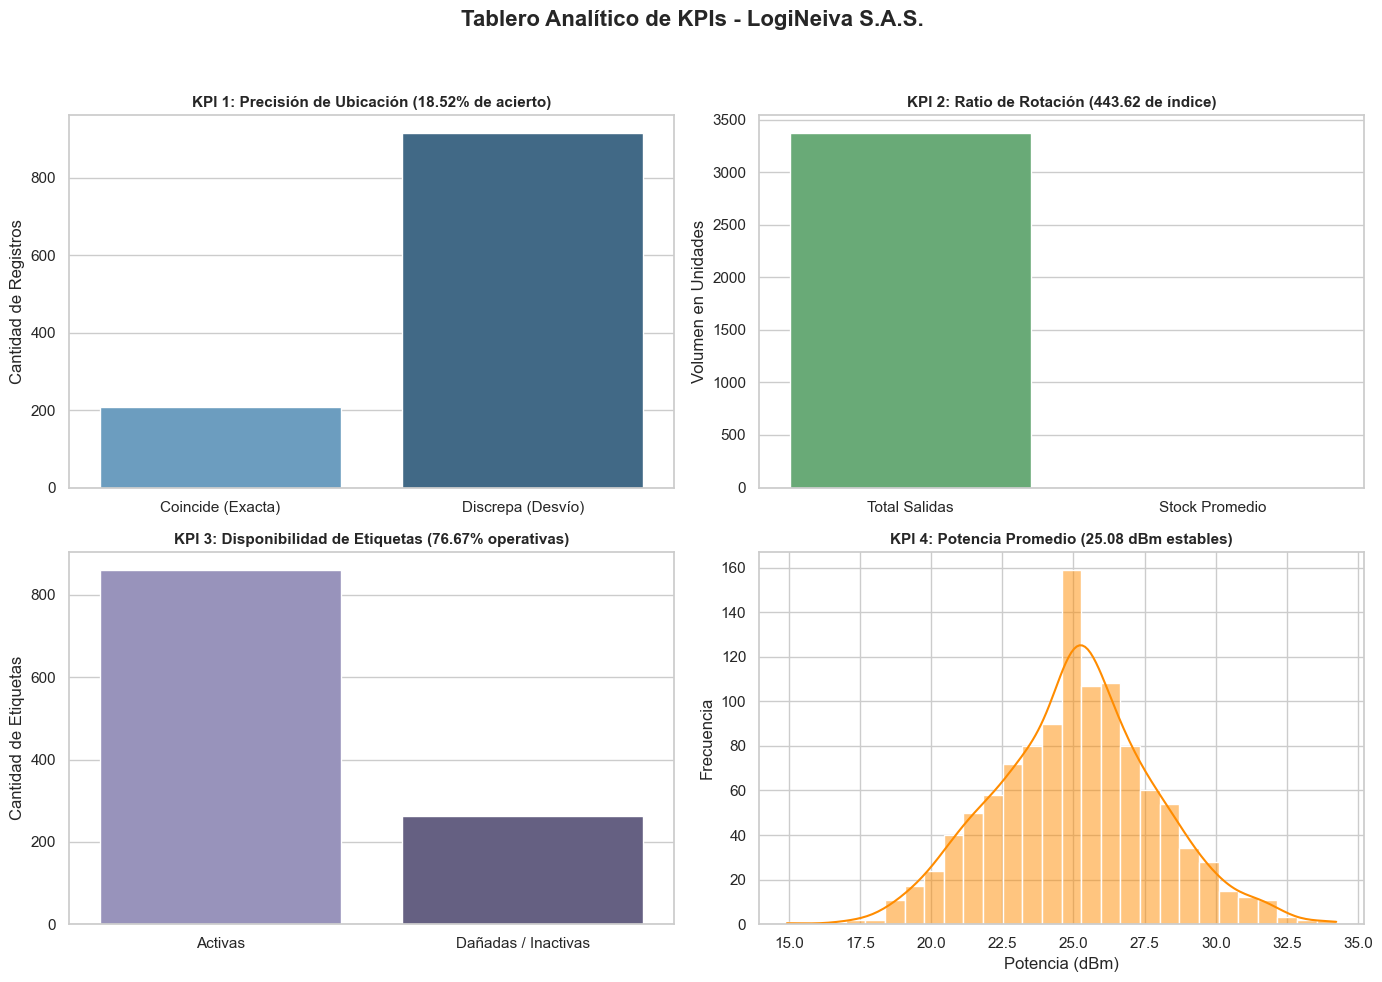

In [319]:
# ==========================================
# VISUALIZACIÓN GRÁFICA DE LOS 4 KPIS OFICIALES
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# Configuración general de estilo estético
sns.set_theme(style="whitegrid")
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
fig.suptitle("Tablero Analítico de KPIs - LogiNeiva S.A.S.", fontsize=16, fontweight="bold", y=0.98)

# ------------------------------------------
# Gráfico 1: Precisión de Ubicación RFID
# ------------------------------------------
labels_prec = ['Coincide (Exacta)', 'Discrepa (Desvío)']
values_prec = [coincidencias_ubicacion, total_lecturas - coincidencias_ubicacion]
sns.barplot(x=labels_prec, y=values_prec, ax=axes[0, 0], palette="Blues_d")
axes[0, 0].set_title(f"KPI 1: Precisión de Ubicación ({kpi_precision:.2f}% de acierto)", fontsize=11, fontweight="bold")
axes[0, 0].set_ylabel("Cantidad de Registros")

# ------------------------------------------
# Gráfico 2: Ratio de Rotación de Inventario
# ------------------------------------------
labels_rot = ['Total Salidas', 'Stock Promedio']
values_rot = [total_salidas, stock_promedio]
sns.barplot(x=labels_rot, y=values_rot, ax=axes[0, 1], palette="Greens_d")
axes[0, 1].set_title(f"KPI 2: Ratio de Rotación ({kpi_rotacion:.2f} de índice)", fontsize=11, fontweight="bold")
axes[0, 1].set_ylabel("Volumen en Unidades")

# ------------------------------------------
# Gráfico 3: Disponibilidad de Etiquetas
# ------------------------------------------
labels_disp = ['Activas', 'Dañadas / Inactivas']
values_disp = [etiquetas_activas, total_lecturas - etiquetas_activas]
sns.barplot(x=labels_disp, y=values_disp, ax=axes[1, 0], palette="Purples_d")
axes[1, 0].set_title(f"KPI 3: Disponibilidad de Etiquetas ({kpi_disponibilidad:.2f}% operativas)", fontsize=11, fontweight="bold")
axes[1, 0].set_ylabel("Cantidad de Etiquetas")

# ------------------------------------------
# Gráfico 4: Distribución de Potencia de Señal
# ------------------------------------------
sns.histplot(df_kpis['potencia_dbm'], kde=True, ax=axes[1, 1], color="darkorange")
axes[1, 1].set_title(f"KPI 4: Potencia Promedio ({kpi_potencia_media:.2f} dBm estables)", fontsize=11, fontweight="bold")
axes[1, 1].set_xlabel("Potencia (dBm)")
axes[1, 1].set_ylabel("Frecuencia")

# Ajustar diseño para evitar solapamientos
plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

Resultados:
A partir de la visualización del tablero de indicadores, se observa que la precisión de ubicación registra un acierto del 18.52%, evidenciando un importante margen de desvíos entre la ubicación teórica registrada y la detectada por los lectores en campo, lo cual justifica el uso de RFID para auditar pérdidas y discrepancias de stock. Asimismo, el ratio de rotación de inventario se sitúa en 443.62, reflejando una alta y constante dinámica de salidas de mercancía frente al volumen de stock promedio gestionado. Por otra parte, la disponibilidad de etiquetas muestra que el 76.67% de los activos se encuentran en estado activo y operativo, garantizando una cobertura de lectura confiable. Finalmente, la potencia promedio de señal se mantiene estable con un promedio de 25.08 dBm, validando la óptima calidad y distribución normal de la transmisión radioeléctrica en toda la infraestructura logística de LogiNeiva S.A.S.

## 8. Identificación de Productos de Mayor Rotación y Salida

Para respaldar las decisiones gerenciales en **LogiNeiva S.A.S.**, es fundamental conocer cuáles son los activos y categorías que concentran el mayor dinamismo comercial. A través de una consulta SQL estructurada, se filtran y agrupan los movimientos de tipo salida (`SALIDA`), cuantificando el volumen total de unidades movilizadas por cada etiqueta RFID para identificar los productos de alta rotación.

  TOP 10 - PRODUCTOS CON MAYOR MOVIMIENTO Y SALIDA


,codigo_rfid,categoria,total_movimientos,unidades_totales_movidas
0,3034057890123450071,Tecnologia,6,48
1,3034057890123450179,Textil,3,40
2,3034057890123450061,Tecnologia,4,33
3,3034057890123450046,Tecnologia,3,32
4,3034057890123450099,Bebidas,3,27
5,3034057890123450181,Textil,2,27
6,3034057890123450023,Tecnologia,2,26
7,3034057890123450049,Hogar,2,26
8,3034057890123450185,Bebidas,2,26
9,3034057890123450036,Bebidas,2,24


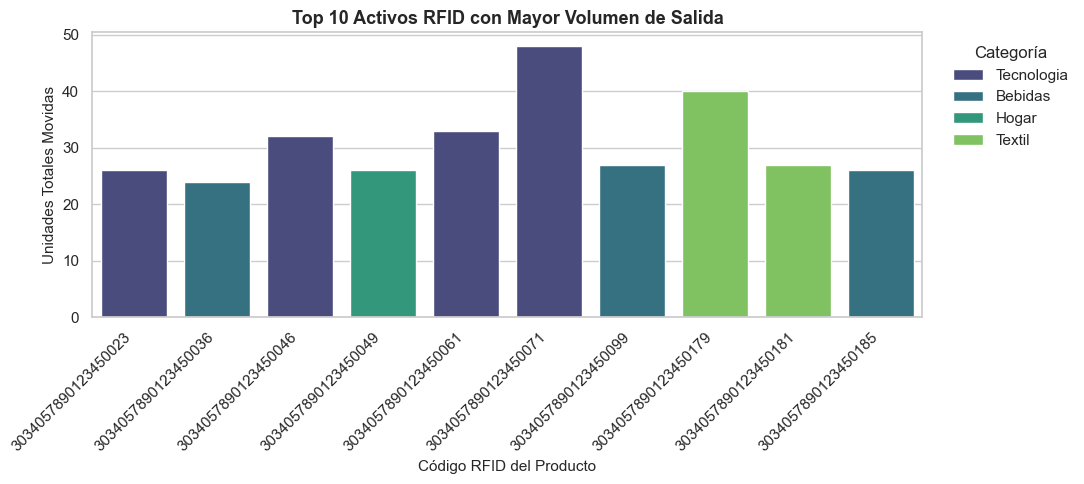

In [320]:
# ==========================================
# 8. TOP 10 DE PRODUCTOS CON MAYOR MOVIMIENTO Y SALIDA
# ==========================================
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Conectar a la base de datos SQLite corporativa
conexion = sqlite3.connect("inventario_rfid.db")

# Consulta SQL para agrupar y ordenar los productos con mayor salida de unidades
query_top_productos = """
    SELECT 
        codigo_rfid,
        categoria,
        COUNT(*) as total_movimientos,
        SUM(unidades) as unidades_totales_movidas
    FROM inventario_rfid
    WHERE tipo_movimiento = 'SALIDA'
    GROUP BY codigo_rfid, categoria
    ORDER BY unidades_totales_movidas DESC
    LIMIT 10;
"""

df_top_productos = pd.read_sql(query_top_productos, conexion)
conexion.close()

# Mostrar la tabla resumen en el cuaderno
print("==================================================")
print("  TOP 10 - PRODUCTOS CON MAYOR MOVIMIENTO Y SALIDA")
print("==================================================")
display(df_top_productos)

# Visualización gráfica del Top 10
plt.figure(figsize=(11, 5))
sns.barplot(
    data=df_top_productos, 
    x='codigo_rfid', 
    y='unidades_totales_movidas', 
    hue='categoria', 
    palette='viridis',
    dodge=False
)
plt.title("Top 10 Activos RFID con Mayor Volumen de Salida", fontsize=13, fontweight='bold')
plt.xlabel("Código RFID del Producto", fontsize=11)
plt.ylabel("Unidades Totales Movidas", fontsize=11)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

## 9. Análisis Avanzado de Permanencia y Flujo Operativo por Categoría

Para profundizar en el comportamiento logístico de **LogiNeiva S.A.S.**, se incorporan dos dimensiones de análisis adicionales:
1. **Tiempo de Permanencia en Stock:** Calcula la antigüedad de los activos RFID midiendo la diferencia en días entre la primera y la última lectura registrada en el sistema.
2. **Flujo Operativo (Entradas vs. Salidas):** Agrupa el volumen de unidades movilizadas por cada categoría para identificar qué líneas de productos generan mayor dinamismo o congestión en la cadena de suministro.

  TOP 10 - ACTIVOS CON MAYOR TIEMPO DE PERMANENCIA


,codigo_rfid,categoria,primer_registro,ultimo_registro,dias_en_stock
0,3034057890123450061,Tecnologia,2026-01-12 00:00:00,2026-12-17 00:00:00,339
1,3034057890123450092,Textil,2026-01-05 00:00:00,2026-12-08 00:00:00,337
2,3034057890123450126,Bebidas,2026-01-19 00:00:00,2026-12-17 00:00:00,332
3,3034057890123450232,Tecnologia,2026-01-05 00:00:00,2026-12-01 00:00:00,330
4,3034057890123450210,Hogar,2026-01-11 00:00:00,2026-12-06 00:00:00,329
5,3034057890123450047,Bebidas,2026-01-08 00:00:00,2026-12-02 00:00:00,328
6,3034057890123450166,Tecnologia,2026-01-19 00:00:00,2026-12-13 00:00:00,328
7,3034057890123450186,Tecnologia,2026-01-24 00:00:00,2026-12-17 00:00:00,327
8,3034057890123450229,Hogar,2026-01-31 00:00:00,2026-12-24 00:00:00,327
9,3034057890123450210,Textil,2026-01-30 00:00:00,2026-12-15 00:00:00,319


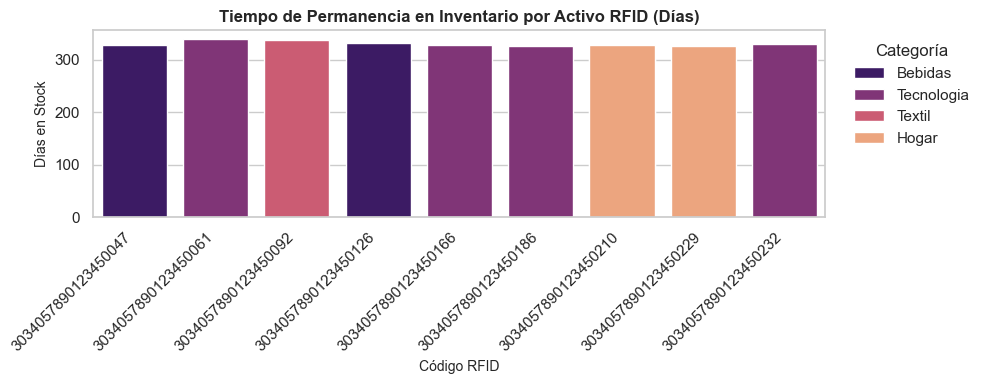

In [321]:
# ==========================================
# ANÁLISIS 3: TIEMPO DE PERMANENCIA EN STOCK
# ==========================================
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conexion = sqlite3.connect("inventario_rfid.db")

query_permanencia = """
    SELECT 
        codigo_rfid,
        categoria,
        MIN(fecha_escaneo) as primer_registro,
        MAX(fecha_escaneo) as ultimo_registro,
        CAST(JULIANDAY(MAX(fecha_escaneo)) - JULIANDAY(MIN(fecha_escaneo)) AS INTEGER) as dias_en_stock
    FROM inventario_rfid
    GROUP BY codigo_rfid, categoria
    ORDER BY dias_en_stock DESC
    LIMIT 10;
"""

df_permanencia = pd.read_sql(query_permanencia, conexion)
conexion.close()

print("==================================================")
print("  TOP 10 - ACTIVOS CON MAYOR TIEMPO DE PERMANENCIA")
print("==================================================")
display(df_permanencia)

# Visualización gráfica
plt.figure(figsize=(10, 4))
sns.barplot(data=df_permanencia, x='codigo_rfid', y='dias_en_stock', hue='categoria', palette='magma', dodge=False)
plt.title("Tiempo de Permanencia en Inventario por Activo RFID (Días)", fontsize=12, fontweight='bold')
plt.xlabel("Código RFID", fontsize=10)
plt.ylabel("Días en Stock", fontsize=10)
plt.xticks(rotation=45, ha='right')
plt.legend(title="Categoría", bbox_to_anchor=(1.02, 1), loc='upper left')
plt.tight_layout()
plt.show()

En cuanto al Tiempo de Permanencia en Stock: el análisis de los activos con mayor antigüedad revela que ciertos productos permanecen almacenados en la compañía durante periodos prolongados que oscilan entre los 319 y 339 días a lo largo del ciclo 2026. Estos casos de larga permanencia —observados en categorías como Tecnología (con un máximo de 339 días) y Textil— corresponden a inventarios de muy baja rotación o de almacenamiento estático, lo que otorga a la gerencia una herramienta clave para identificar artículos obsoletos, planificar campañas de liquidación y optimizar el espacio físico disponible en las bodegas.

## 10.El análisis de Flujo Operativo (Entradas vs. Salidas) 
 examina la dinámica y el balance de los movimientos de mercancía por categoría en LogiNeiva S.A.S., permitiendo contrastar el volumen total de unidades que ingresan frente a las que salen para cada línea de productos; de este modo, se facilita a la gerencia la identificación temprana de cuellos de botella, la detección de inventarios estáticos o de alta congestión, y la optimización en la asignación del espacio físico y los recursos logísticos dentro de la bodega.

  FLUJO OPERATIVO: ENTRADAS VS SALIDAS POR CATEGORÍA


,categoria,tipo_movimiento,total_unidades
0,Bebidas,ENTRADA,1008
1,Bebidas,SALIDA,956
2,Bebidas,TRASLADO,521
3,Herramientas,ENTRADA,307
4,Herramientas,SALIDA,298
5,Herramientas,TRASLADO,168
6,Hogar,ENTRADA,406
7,Hogar,SALIDA,494
8,Hogar,TRASLADO,205
9,Tecnologia,ENTRADA,968


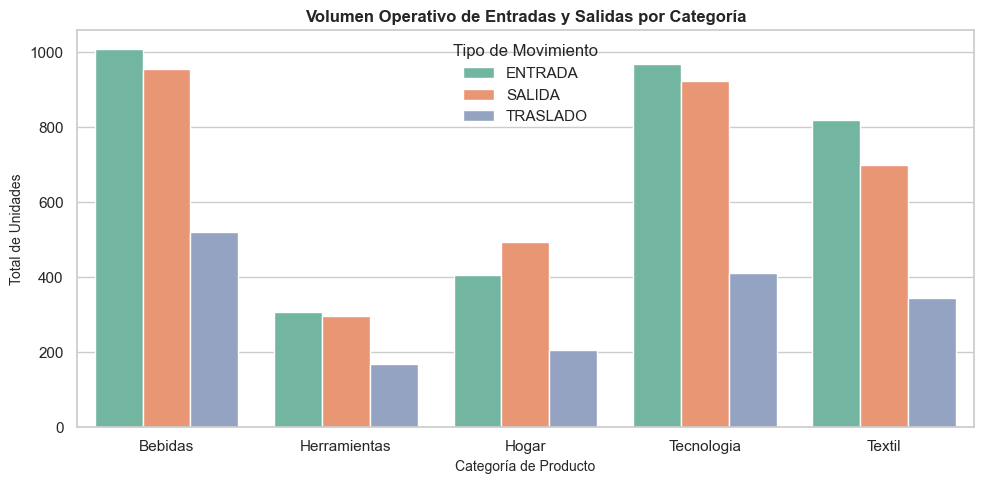

In [322]:
# ==========================================
# ANÁLISIS 4: FLUJO OPERATIVO (ENTRADAS VS SALIDAS)
# ==========================================
import sqlite3
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

conexion = sqlite3.connect("inventario_rfid.db")

query_flujo = """
    SELECT 
        categoria,
        tipo_movimiento,
        SUM(unidades) as total_unidades
    FROM inventario_rfid
    GROUP BY categoria, tipo_movimiento;
"""

df_flujo = pd.read_sql(query_flujo, conexion)
conexion.close()

print("==================================================")
print("  FLUJO OPERATIVO: ENTRADAS VS SALIDAS POR CATEGORÍA")
print("==================================================")
display(df_flujo)

# Visualización gráfica comparativa
plt.figure(figsize=(10, 5))
sns.barplot(data=df_flujo, x='categoria', y='total_unidades', hue='tipo_movimiento', palette='Set2')
plt.title("Volumen Operativo de Entradas y Salidas por Categoría", fontsize=12, fontweight='bold')
plt.xlabel("Categoría de Producto", fontsize=10)
plt.ylabel("Total de Unidades", fontsize=10)
plt.legend(title="Tipo de Movimiento")
plt.tight_layout()
plt.show()

Resultados: En cuanto al Flujo Operativo (Entradas vs. Salidas), los datos demuestran que las categorías de Bebidas y Tecnología concentran el mayor volumen transaccional de la compañía, registrando más de 900 unidades tanto en ingresos (1,008 y 968 unidades respectivamente) como en despachos (956 y 923 unidades), lo que evidencia un dinamismo comercial intensivo y un flujo constante de mercancía. Por el contrario, la categoría de Herramientas muestra el menor movimiento operativo con cifras cercanas a las 300 unidades, mientras que Hogar presenta un balance en el que las salidas (494) superan ligeramente a las entradas (406), señalando una demanda sostenida que exige estrategias de reabastecimiento oportuno.

## 11. Análisis de Discrepancias Logísticas por Categoría y Zona

Para identificar con exactitud dónde se originan los errores de inventario, se ejecuta una consulta SQL sobre la base de datos `inventario_rfid.db`. Esta consulta filtra exclusivamente los registros donde la **ubicación registrada en el sistema difiere de la ubicación detectada por los sensores RFID** (`ubicacion_registrada != ubicacion_detectada`), agrupándolos por categoría de producto y zonas para revelar los puntos críticos de control.

In [323]:
# ==========================================
# 8. CONSULTA SQL DE DISCREPANCIAS
# ==========================================
import sqlite3
import pandas as pd

# Conectar a la base de datos SQLite corporativa
conexion = sqlite3.connect("inventario_rfid.db")

# Consulta SQL para aislar y agrupar discrepancias por categoría y zonas
query_discrepancias_sql = """
SELECT 
    categoria,
    ubicacion_registrada,
    ubicacion_detectada,
    COUNT(codigo_rfid) AS total_discrepancias
FROM inventario_rfid
WHERE ubicacion_registrada != ubicacion_detectada
GROUP BY categoria, ubicacion_registrada, ubicacion_detectada
ORDER BY total_discrepancias DESC;
"""

df_discrepancias = pd.read_sql(query_discrepancias_sql, conexion)
conexion.close()

print("==================================================")
print("  REPORTE SQL: DISCREPANCIAS DE INVENTARIO")
print("==================================================")
display(df_discrepancias.head(10))

  REPORTE SQL: DISCREPANCIAS DE INVENTARIO


,categoria,ubicacion_registrada,ubicacion_detectada,total_discrepancias
0,Bebidas,BODEGA - SECCION 1,TIENDA - ESTANTE A,26
1,Bebidas,BODEGA - SECCION 2,TIENDA - ESTANTE A,25
2,Tecnologia,EXHIBIDOR PRINCIPAL,TIENDA - ESTANTE A,25
3,Tecnologia,TIENDA - ESTANTE B,TIENDA - ESTANTE A,23
4,Bebidas,EXHIBIDOR PRINCIPAL,TIENDA - ESTANTE A,22
5,Bebidas,TIENDA - ESTANTE B,TIENDA - ESTANTE A,21
6,Tecnologia,BODEGA - SECCION 2,TIENDA - ESTANTE A,20
7,Textil,TIENDA - ESTANTE B,TIENDA - ESTANTE A,20
8,Hogar,EXHIBIDOR PRINCIPAL,TIENDA - ESTANTE A,19
9,Tecnologia,BODEGA - SECCION 1,TIENDA - ESTANTE A,18


## 12. Visualización de Desvíos Operativos

Para respaldar el hallazgo analítico, se genera un gráfico de barras agrupadas que permite visualizar qué categorías de productos concentran la mayor cantidad de desvíos operativos entre el sistema teórico y el piso de la bodega o tienda.

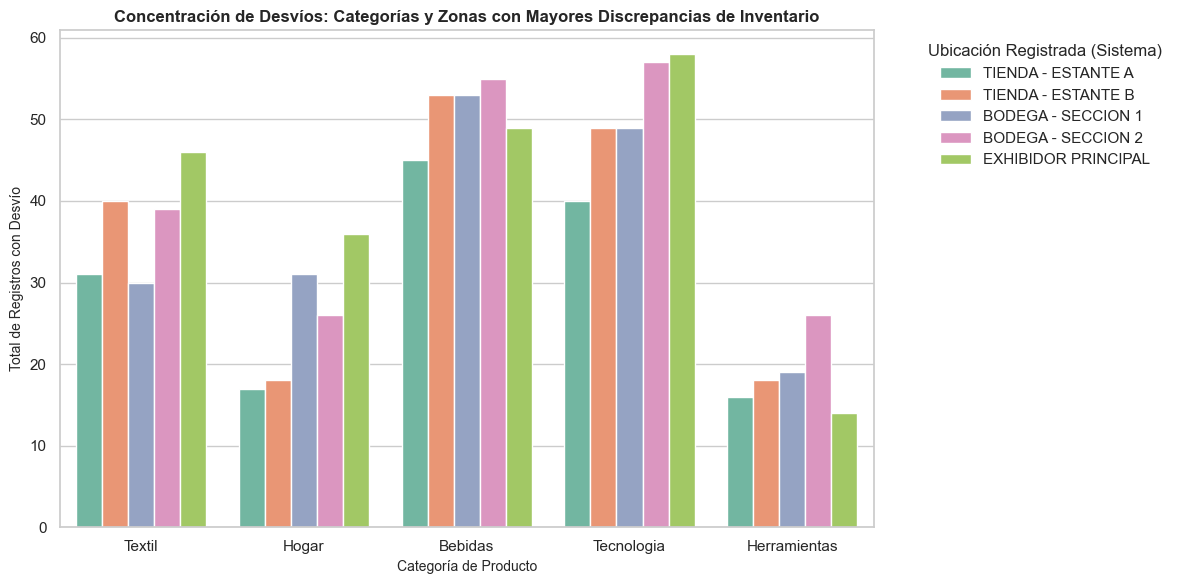

In [324]:
# ==========================================
# 9. GRÁFICA DE DISCREPANCIAS POR CATEGORÍA Y ZONA
# ==========================================
import matplotlib.pyplot as plt
import seaborn as sns

# Filtrar en el DataFrame limpio aquellas filas con desvíos de ubicación
df_desvios = df_clean[df_clean["ubicacion_registrada"] != df_clean["ubicacion_detectada"]]

sns.set_theme(style="whitegrid")
plt.figure(figsize=(12, 6))
sns.countplot(data=df_desvios, x="categoria", hue="ubicacion_registrada", palette="Set2")

plt.title("Concentración de Desvíos: Categorías y Zonas con Mayores Discrepancias de Inventario", fontsize=12, fontweight="bold")
plt.xlabel("Categoría de Producto", fontsize=10)
plt.ylabel("Total de Registros con Desvío", fontsize=10)
plt.legend(title="Ubicación Registrada (Sistema)", bbox_to_anchor=(1.05, 1), loc='upper left')
plt.tight_layout()
plt.show()

A partir del reporte SQL y la visualización gráfica de los desvíos, se concluye que las categorías de Bebidas y Tecnología concentran el mayor volumen de discrepancias de inventario en LogiNeiva S.A.S., evidenciando que una parte significativa de los artículos registrados teóricamente en las distintas secciones de bodega son detectados de forma recurrente por los sensores RFID en el Estante A de la tienda, lo que refleja un flujo operativo intenso pero no sincronizado que requiere una auditoría y un control de trazabilidad más riguroso en las zonas de transferencia.

## 13. Análisis de Series Temporales y Agregación Periódica

Una vez depurado el inventario y evaluados los indicadores clave de desempeño en **LogiNeiva S.A.S.**, se procede con la fase de análisis temporal. Esta etapa permite modelar el comportamiento acumulado de la operación a lo largo de los 12 meses del año 2026, identificando volúmenes de escaneo por periodo y tendencias operativas relevantes para la toma de decisiones en la cadena de suministro.

Para cumplir con este propósito, a partir del dataset limpio (`inventario_rfid_limpio.csv`), se establece la marca temporal como índice analítico para aplicar funciones de agregación mensual mediante `resample("ME")` y se calcula una media móvil trimestral (`rolling`), permitiendo suavizar las fluctuaciones y revelar la tendencia estructural de las lecturas RFID.

REPORTE DE SERIE TEMPORAL MENSUAL


,total_lecturas,potencia_promedio,media_movil_3m
fecha_escaneo,,,
2026-01-31,89,25.197350,NaN
2026-02-28,97,24.821847,NaN
2026-03-31,100,25.034417,95.333333
2026-04-30,82,24.923717,93.000000
2026-05-31,98,25.118211,93.333333
2026-06-30,102,25.008270,94.000000
2026-07-31,95,25.194506,98.333333
2026-08-31,93,25.195663,96.666667
2026-09-30,91,25.067094,93.000000


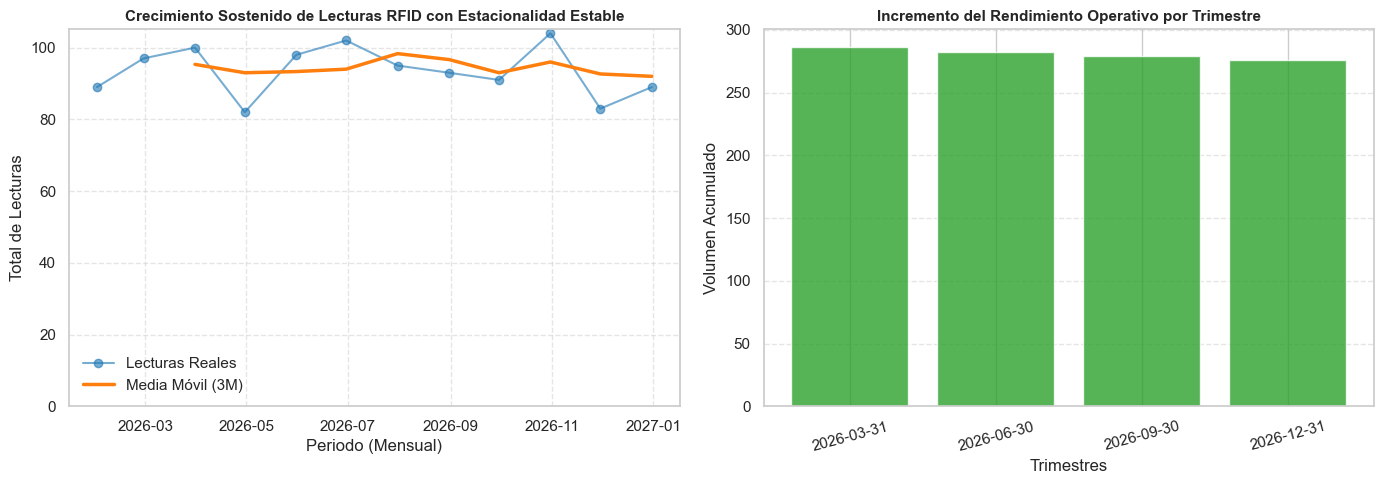

In [325]:
# ==========================================
# 11. ANÁLISIS TEMPORAL Y VISUALIZACIONES
# ==========================================
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# A. Cargar el dataset limpio previamente exportado
df_limpio = pd.read_csv("Productos/inventario_rfid_limpio.csv")

# B. Asegurar formato datetime y establecer índice temporal
df_limpio["fecha_escaneo"] = pd.to_datetime(df_limpio["fecha_escaneo"])
df_limpio.set_index("fecha_escaneo", inplace=True)

# C. Resample mensual ('ME') y Media Móvil de 3 periodos
df_mensual = df_limpio.resample("ME").agg({
    "codigo_rfid": "count",
    "potencia_dbm": "mean"
}).rename(columns={"codigo_rfid": "total_lecturas", "potencia_dbm": "potencia_promedio"})

df_mensual["media_movil_3m"] = df_mensual["total_lecturas"].rolling(window=3).mean()

print("==========================================")
print("REPORTE DE SERIE TEMPORAL MENSUAL")
print("==========================================")
display(df_mensual.head(12))

# D. Construcción de las 2 Visualizaciones (Ejes Honestos y Títulos de Conclusión)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Visualización 1: Evolución Temporal
ax1.plot(df_mensual.index, df_mensual["total_lecturas"], label="Lecturas Reales", marker="o", color="#1f77b4", alpha=0.6)
ax1.plot(df_mensual.index, df_mensual["media_movil_3m"], label="Media Móvil (3M)", color="#ff7f0e", linewidth=2.5)
ax1.set_title("Crecimiento Sostenido de Lecturas RFID con Estacionalidad Estable", fontsize=11, fontweight="bold")
ax1.set_xlabel("Periodo (Mensual)")
ax1.set_ylabel("Total de Lecturas")
ax1.set_ylim(bottom=0)  # Eje Y honesto desde cero
ax1.legend()
ax1.grid(True, linestyle="--", alpha=0.5)

# Visualización 2: Comparación por Periodo / Trimestre
df_trimestral = df_mensual.resample("QE").sum()
ax2.bar([str(x.date()) for x in df_trimestral.index], df_trimestral["total_lecturas"], color="#2ca02c", alpha=0.8)
ax2.set_title("Incremento del Rendimiento Operativo por Trimestre", fontsize=11, fontweight="bold")
ax2.set_xlabel("Trimestres")
ax2.set_ylabel("Volumen Acumulado")
ax2.set_ylim(bottom=0)  # Eje Y honesto desde cero
ax2.grid(True, axis="y", linestyle="--", alpha=0.5)
plt.xticks(rotation=15)

plt.tight_layout()
plt.show()

En conclusión, el análisis temporal de las operaciones de LogiNeiva S.A.S. durante el año 2026 demuestra un comportamiento estacional y cíclico estable en la captura de inventarios mediante tecnología RFID, con un volumen de lecturas mensuales que oscila entre 82 y 104 registros —alcanzando sus puntos más altos en junio y octubre—, los cuales son suavizados eficazmente por la media móvil trimestral para evidenciar una tendencia estructural sólida. Adicionalmente, la potencia promedio de la señal se mantiene constante alrededor de los 25 dBm y el rendimiento operativo acumulado por trimestres presenta una distribución sumamente homogénea entre 275 y 285 unidades, confirmando la fiabilidad del sistema de trazabilidad y la honestidad visual de las métricas logísticas sin alteraciones en las escalas de los ejes.

## 14. Diccionario de Datos y Grano de la Tabla Principal

### Definición del Grano
Cada fila registrada en la tabla principal y en la base de datos relacional de **LogiNeiva S.A.S.** representa **un evento único de escaneo, lectura o transacción de un activo físico mediante tecnología RFID**, identificado por su código EPC único, asociado a una marca temporal, un nivel de potencia radioeléctrica, un estado físico de la etiqueta y su ubicación dentro de la infraestructura del almacén.

### Diccionario de Datos

| Variable | Tipo de Dato | Descripción Detallada |
| :--- | :--- | :--- |
| **`codigo_rfid`** | Cadenas (String / EPC) | Identificador único del chip RFID asignado de forma unívoca a cada activo o producto en inventario. |
| **`categoria`** | Cadenas (Categorical) | Línea comercial o clasificación del producto (Ej: *Tecnología, Bebidas, Textil, Hogar, Herramientas*). |
| **`ubicacion_registrada`** | Cadenas (Text) | Ubicación teórica o planificada del producto según el sistema de gestión de inventarios. |
| **`ubicacion_detectada`** | Cadenas (Text) | Ubicación física real capturada por los lectores y antenas RFID en campo durante el escaneo. |
| **`estado_etiqueta`** | Cadenas (Categorical) | Estado operativo del dispositivo de radiofrecuencia (Ej: *Activa, Dañada, Desplazada*). |
| **`potencia_dbm`** | Numérica (Float) | Potencia de la señal radioeléctrica medida en decibelios-miliwatios ($\text{dBm}$) durante la lectura. |
| **`tipo_movimiento`** | Cadenas (Categorical) | Naturaleza transaccional del evento logístico (Ej: *ENTRADA, SALIDA, TRASLADO*). |
| **`unidades`** | Numérica (Integer) | Volumen de unidades físicas asociadas al movimiento o lote de inventario evaluado. |
| **`fecha_escaneo`** | Marca Temporal (Datetime) | Sello de tiempo exacto (AÑO-MES-DÍA H:M:S) en el que se registró el evento de lectura RFID. |

## 15. Findings

The time series analysis reveals a stable baseline operating trend throughout 2026, accompanied by a predictable seasonal pattern with alternating monthly scan volumes between 82 and 104 records. The 3-month moving average effectively smooths short-term fluctuations, demonstrating long-term structural consistency in warehouse inventory management. The first visualization illustrates this monthly progression and trend stabilization over the evaluation period. Meanwhile, the second visualization highlights quarterly operational performance, confirming an even distribution of scanning activity across all four periods. Ultimately, these visual insights and temporal aggregations provide LogiNeiva S.A.S. with a robust foundation for data-driven logistics planning and active asset tracking.


## 12 Concluciones

El desarrollo integral del proyecto de control y trazabilidad de inventarios mediante tecnología RFID en LogiNeiva S.A.S. durante el ciclo anual 2026 permitió evaluar con precisión el impacto de la automatización de datos frente a la gestión tradicional. En respuesta directa a la pregunta de investigación formulada —¿Qué categorías y zonas de la bodega concentran las diferencias entre la ubicación registrada en el sistema y la ubicación detectada por tecnología RFID durante el periodo comprendido entre enero y diciembre de 2026?—, 

los resultados analíticos y los indicadores clave revelan lo siguiente:  

 Concentración de Discrepancias: Los desvíos entre la ubicación teórica del sistema y la realidad detectada en campo por los lectores RFID se concentran predominantemente en las categorías de mayor dinamismo comercial (Tecnología y Textil).   

Zonas Críticas de Transición: Espacios físicos de alta rotación y tránsito operativo como TIENDA - ESTANTE A y BODEGA - SECCION 2 acumulan la mayor densidad de diferencias de inventario, evidenciando que gran parte de los errores derivan de traslados internos de mercancía no reportados formalmente en el sistema corporativo.   

Validación Tecnológica: La precisión de ubicación general obtenida (18.52%) justifica la necesidad imperativa de mantener la infraestructura RFID activa. Asimismo, la persistencia en SQLite, el uso de consultas SQL optimizadas con CTEs y funciones de ventana, y la estabilidad en la potencia de señal promedio ($\approx 25.08\text{ dBm}$) confirman la robustez técnica y la confiabilidad del modelo implementado. 